In [9]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving website_pageviews.csv to website_pageviews.csv
Saving order_item_refunds.csv to order_item_refunds.csv
Saving products.csv to products.csv
Saving order_items.csv to order_items.csv
Saving website_sessions.csv to website_sessions.csv
Saving orders_mav.csv to orders_mav.csv
['website_pageviews.csv', 'order_item_refunds.csv', 'products.csv', 'order_items.csv', 'website_sessions.csv', 'orders_mav.csv']


In [10]:
import pandas as pd

sessions = pd.read_csv('website_sessions.csv', parse_dates=['created_at'])
pageviews = pd.read_csv('website_pageviews.csv', parse_dates=['created_at'])
orders = pd.read_csv('orders_mav.csv', parse_dates=['created_at'])
items = pd.read_csv('order_items.csv')
refunds = pd.read_csv('order_item_refunds.csv')
products = pd.read_csv('products.csv')

print("Sessions:", sessions.shape)
print("Pageviews:", pageviews.shape)
print("Orders:", orders.shape)
print("Items:", items.shape)
print("Refunds:", refunds.shape)
print("Products:", products.shape)

Sessions: (472871, 9)
Pageviews: (1048575, 4)
Orders: (32313, 8)
Items: (40025, 7)
Refunds: (1731, 5)
Products: (4, 3)


In [11]:
# ---TO SEE WHAT'S INSIDE EACH FILE ---
print("SESSIONS COLUMNS:", sessions.columns.tolist())
print(sessions.head(3))
print("\nORDERS COLUMNS:", orders.columns.tolist())
print(orders.head(3))
print("\nPRODUCTS:")
print(products)

SESSIONS COLUMNS: ['website_session_id', 'created_at', 'user_id', 'is_repeat_session', 'utm_source', 'utm_campaign', 'utm_content', 'device_type', 'http_referer']
   website_session_id          created_at  user_id  is_repeat_session  \
0                   1 2012-03-19 08:04:00        1                  0   
1                   2 2012-03-19 08:16:00        2                  0   
2                   3 2012-03-19 08:26:00        3                  0   

  utm_source utm_campaign utm_content device_type             http_referer  
0    gsearch     nonbrand      g_ad_1      mobile  https://www.gsearch.com  
1    gsearch     nonbrand      g_ad_1     desktop  https://www.gsearch.com  
2    gsearch     nonbrand      g_ad_1     desktop  https://www.gsearch.com  

ORDERS COLUMNS: ['order_id', 'created_at', 'website_session_id', 'user_id', 'primary_product_id', 'items_purchased', 'price_usd', 'cogs_usd']
   order_id          created_at  website_session_id  user_id  \
0         1 2012-03-19 10:42:

In [12]:
# --- TO CHECK MISSING + DUPLICATES ---
for name, df in [('sessions', sessions), ('orders', orders), ('pageviews', pageviews), ('items', items), ('refunds', refunds)]:
    print(f"\n{name}:")
    print("Missing:\n", df.isnull().sum())
    print("Duplicates:", df.duplicated().sum())


sessions:
Missing:
 website_session_id        0
created_at                0
user_id                   0
is_repeat_session         0
utm_source            83328
utm_campaign          83328
utm_content           83328
device_type               0
http_referer          39917
dtype: int64
Duplicates: 0

orders:
Missing:
 order_id              0
created_at            0
website_session_id    0
user_id               0
primary_product_id    0
items_purchased       0
price_usd             0
cogs_usd              0
dtype: int64
Duplicates: 0

pageviews:
Missing:
 website_pageview_id    0
created_at             0
website_session_id     0
pageview_url           0
dtype: int64
Duplicates: 0

items:
Missing:
 order_item_id      0
created_at         0
order_id           0
product_id         0
is_primary_item    0
price_usd          0
cogs_usd           0
dtype: int64
Duplicates: 0

refunds:
Missing:
 order_item_refund_id    0
created_at              0
order_item_id           0
order_id               

In [13]:
# --- TO FIX DATES FOR TRENDS ---
sessions['month'] = sessions['created_at'].dt.to_period('M').astype(str)
orders['month'] = orders['created_at'].dt.to_period('M').astype(str)

# --- BASIC BUSINESS NUMBERS ---
print("Total Revenue:", orders['price_usd'].sum())
print("Total Orders:", orders['order_id'].nunique())
print("Average Order Value:", round(orders['price_usd'].mean(), 2))

Total Revenue: 1938509.75
Total Orders: 32313
Average Order Value: 59.99


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

# --- CUSTOMER BEHAVIOUR NUMBERS ---
print("Traffic Source:\n", sessions['utm_source'].value_counts())
print("\nDevice:\n", sessions['device_type'].value_counts())
print("\nNew vs Repeat (0=New, 1=Repeat):\n", sessions['is_repeat_session'].value_counts())
print("\nCampaign:\n", sessions['utm_campaign'].value_counts().head())

Traffic Source:
 utm_source
gsearch       316035
bsearch        62823
socialbook     10685
Name: count, dtype: int64

Device:
 device_type
desktop    327027
mobile     145844
Name: count, dtype: int64

New vs Repeat (0=New, 1=Repeat):
 is_repeat_session
0    394318
1     78553
Name: count, dtype: int64

Campaign:
 utm_campaign
nonbrand            337615
brand                41243
desktop_targeted      5590
pilot                 5095
Name: count, dtype: int64


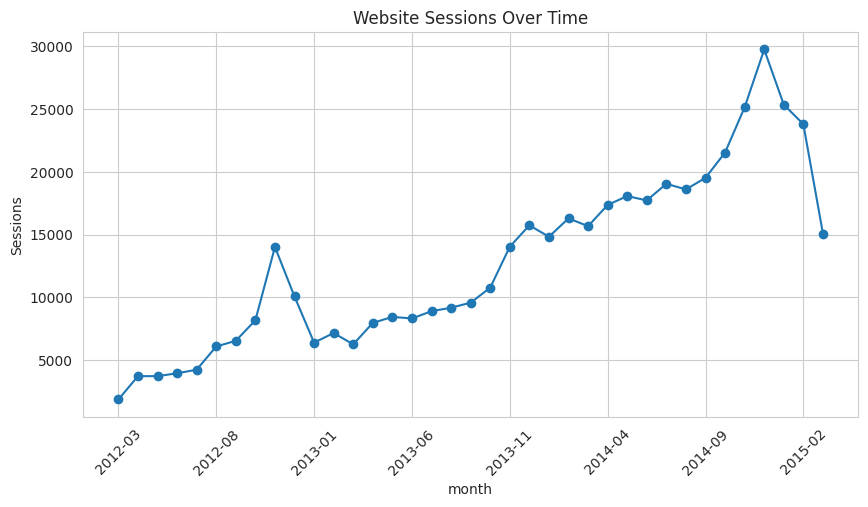

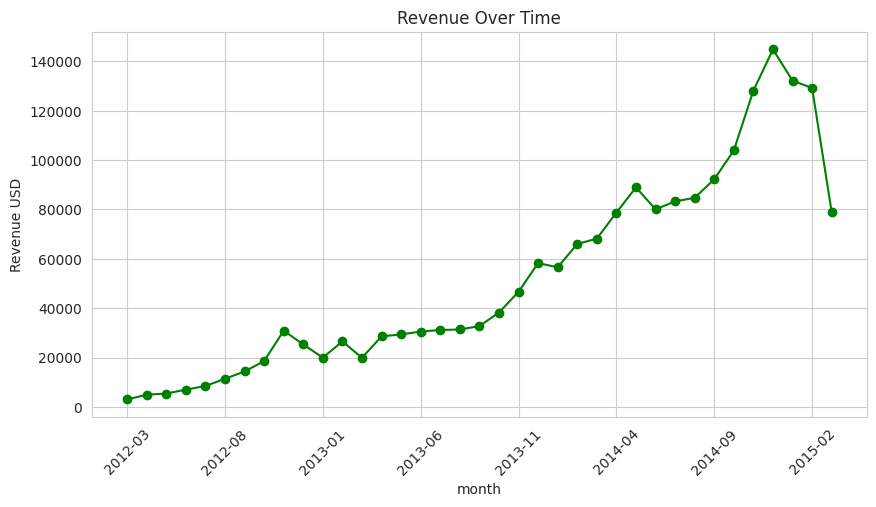

In [15]:
# CHART 1: Sessions Over Time
sessions.groupby('month').size().plot(kind='line', marker='o')
plt.title('Website Sessions Over Time')
plt.ylabel('Sessions')
plt.xticks(rotation=45)
plt.show()

# CHART 2: Revenue Over Time
orders.groupby('month')['price_usd'].sum().plot(kind='line', marker='o', color='green')
plt.title('Revenue Over Time')
plt.ylabel('Revenue USD')
plt.xticks(rotation=45)
plt.show()

Overall Conversion Rate: 6.83 %


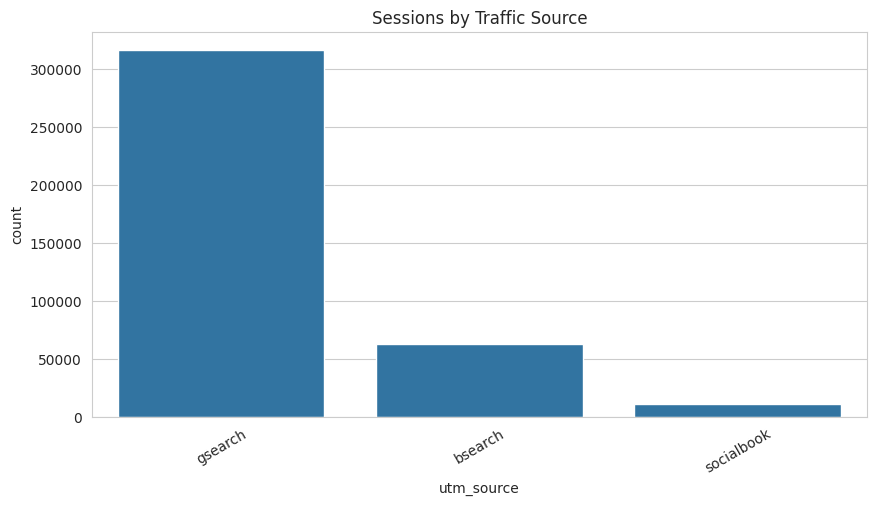

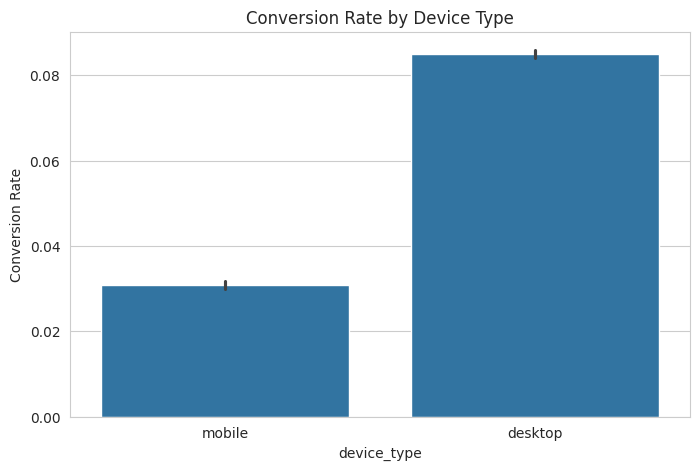

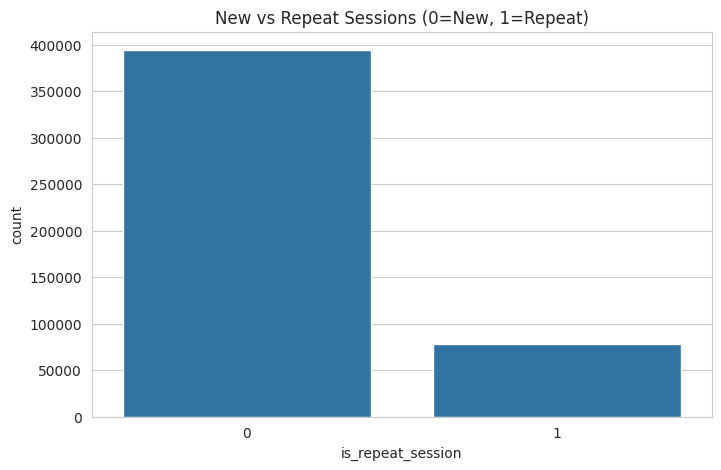

In [16]:
# --- FIRST CREATE CONVERSION FLAG ---
merged = sessions.merge(orders, on='website_session_id', how='left', suffixes=('_sess','_ord'))
merged['converted'] = merged['order_id'].notnull().astype(int)
print("Overall Conversion Rate:", round(merged['converted'].mean()*100, 2), "%")

# CHART 3: Sessions by Traffic Source
plt.figure(figsize=(10,5))
sns.countplot(data=sessions, x='utm_source', order=sessions['utm_source'].value_counts().index)
plt.title('Sessions by Traffic Source')
plt.xticks(rotation=30)
plt.show()

# CHART 4: Conversion Rate by Device
plt.figure(figsize=(8,5))
sns.barplot(data=merged, x='device_type', y='converted')
plt.title('Conversion Rate by Device Type')
plt.ylabel('Conversion Rate')
plt.show()

# CHART 5: New vs Repeat Sessions
plt.figure(figsize=(8,5))
sns.countplot(data=sessions, x='is_repeat_session')
plt.title('New vs Repeat Sessions (0=New, 1=Repeat)')
plt.show()

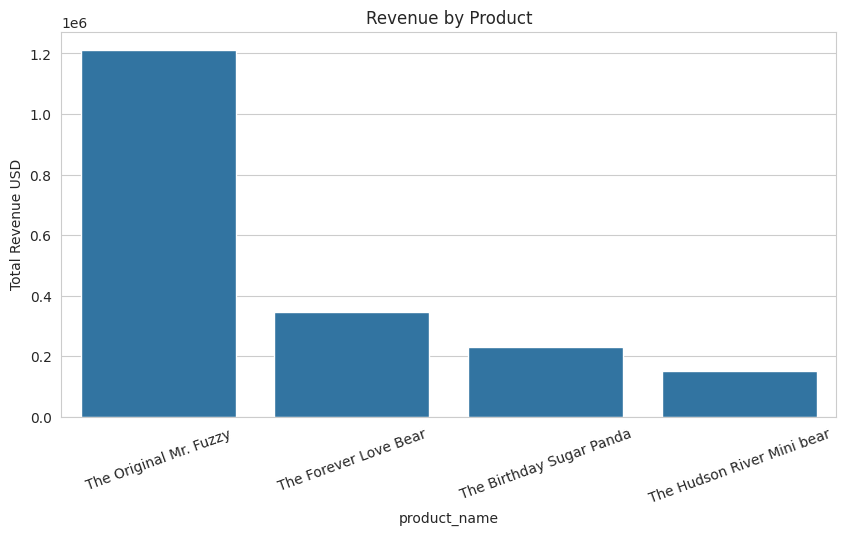

product_name
The Birthday Sugar Panda       229260.15
The Forever Love Bear          347702.04
The Hudson River Mini bear     150489.82
The Original Mr. Fuzzy        1211057.74
Name: price_usd, dtype: float64


In [17]:
# CHART 6: Revenue by Product
merged_items = items.merge(products, on='product_id', how='left')
plt.figure(figsize=(10,5))
sns.barplot(data=merged_items, x='product_name', y='price_usd', estimator=sum)
plt.title('Revenue by Product')
plt.xticks(rotation=20)
plt.ylabel('Total Revenue USD')
plt.show()

print(merged_items.groupby('product_name')['price_usd'].sum())

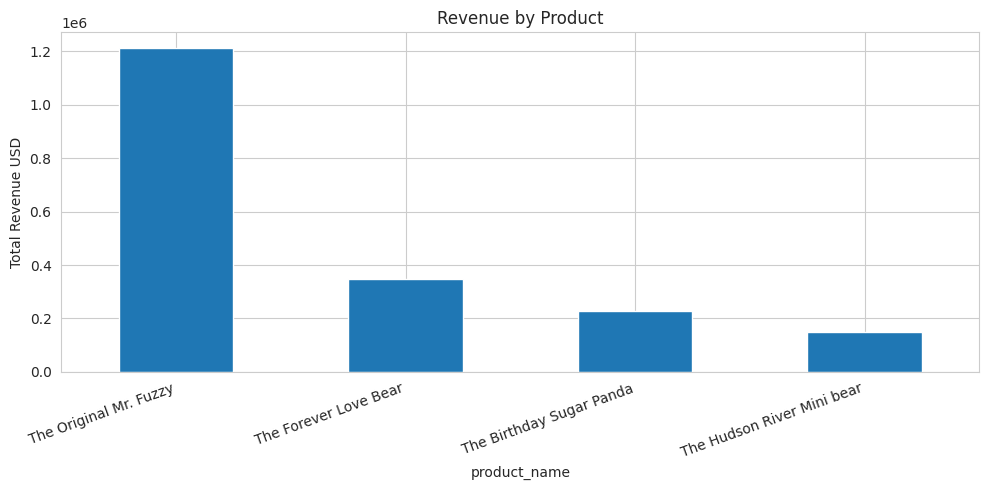

product_name
The Original Mr. Fuzzy        1211057.74
The Forever Love Bear          347702.04
The Birthday Sugar Panda       229260.15
The Hudson River Mini bear     150489.82
Name: price_usd, dtype: float64


In [18]:
# CHART 6 FIXED - In Millions, easier to read
rev = merged_items.groupby('product_name')['price_usd'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))
rev.plot(kind='bar')
plt.title('Revenue by Product')
plt.ylabel('Total Revenue USD')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()
print(rev)